In [4]:
import os

R_HOME = r"C:\Users\Bugra.Tasci\AppData\Local\Programs\R\R-4.6.2"
os.environ["R_HOME"] = R_HOME
os.environ["PATH"] = os.path.join(R_HOME, "bin", "x64") + ";" + os.environ["PATH"]
os.add_dll_directory(os.path.join(R_HOME, "bin", "x64"))

from rpy2.robjects.packages import importr
importr("glmnet")
print("R baglantisi tamam")

R baglantisi tamam


In [5]:
import pandas as pd

dt_simulated_weekly = pd.read_csv("dt_simulated_weekly.csv")
dt_prophet_holidays = pd.read_csv("dt_prophet_holidays.csv")

print(dt_simulated_weekly.shape)
print(dt_prophet_holidays.shape)
dt_simulated_weekly.head()

(208, 12)
(87651, 4)


,DATE,revenue,tv_S,ooh_S,print_S,facebook_I,search_clicks_P,search_S,competitor_sales_B,facebook_S,events,newsletter
0,2015-11-23,2.754372e+06,22358.346667,0.0,12728.488889,2.430128e+07,0.000000,0.000000,8125009,7607.132915,na,19401.653846
1,2015-11-30,2.584277e+06,28613.453333,0.0,0.000000,5.527033e+06,9837.238486,4133.333333,7901549,1141.952450,na,14791.000000
2,2015-12-07,2.547387e+06,0.000000,132278.4,453.866667,1.665159e+07,12044.119653,3786.666667,8300197,4256.375378,na,14544.000000
3,2015-12-14,2.875220e+06,83450.306667,0.0,17680.000000,1.054977e+07,12268.070319,4253.333333,8122883,2800.490677,na,2800.000000
4,2015-12-21,2.215953e+06,0.000000,277336.0,0.000000,2.934090e+06,9467.248023,3613.333333,7105985,689.582605,na,15478.000000


In [6]:
from robyn.data.entities.mmmdata import MMMData

mmm_data_spec = MMMData.MMMDataSpec(
    dep_var="revenue",
    dep_var_type="revenue",
    date_var="DATE",
    paid_media_spends=["tv_S", "ooh_S", "print_S", "facebook_S", "search_S"],
    paid_media_vars=["tv_S", "ooh_S", "print_S", "facebook_I", "search_clicks_P"],
    organic_vars=["newsletter"],
    context_vars=["competitor_sales_B", "events"],
    window_start="2016-01-01",
    window_end="2018-12-31",
)
mmm_data = MMMData(data=dt_simulated_weekly, mmmdata_spec=mmm_data_spec)
print("Model verisi tanimlandi")

2026-11-11 14:24:38,326 - robyn - INFO - Logging is set up to console only.


Model verisi tanimlandi


In [7]:
from robyn.data.entities.holidays_data import HolidaysData

holidays_data = HolidaysData(
    dt_holidays=dt_prophet_holidays,
    prophet_vars=["trend", "season", "holiday"],
    prophet_country="DE",
    prophet_signs=["default", "default", "default"],
)
print("Tatil verisi tanimlandi")

Tatil verisi tanimlandi


In [8]:
from robyn.data.entities.holidays_data import HolidaysData

holidays_data = HolidaysData(
    dt_holidays=dt_prophet_holidays,
    prophet_vars=["trend", "season", "holiday"],
    prophet_country="DE",
    prophet_signs=["default", "default", "default"],
)
print("Tatil verisi tanimlandi")

Tatil verisi tanimlandi


In [9]:
from robyn.data.entities.hyperparameters import Hyperparameters, ChannelHyperparameters
from robyn.data.entities.enums import AdstockType

hyperparameters = Hyperparameters(
    hyperparameters={
        "tv_S":       ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0.3, 0.8]),
        "ooh_S":      ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0.1, 0.4]),
        "print_S":    ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0.1, 0.4]),
        "facebook_S": ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0, 0.3]),
        "search_S":   ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0, 0.3]),
        "newsletter": ChannelHyperparameters(alphas=[0.5, 3], gammas=[0.3, 1], thetas=[0.1, 0.4]),
    },
    adstock=AdstockType.GEOMETRIC,
    lambda_=[0, 1],
    train_size=[0.5, 0.8],
)
print("Hiperparametreler tanimlandi")

Hiperparametreler tanimlandi


2026-11-11 15:00:20,393 - matplotlib.font_manager - WARNING - Matplotlib is building the font cache; this may take a moment.
2026-11-11 15:00:23,176 - matplotlib.font_manager - INFO - generated new fontManager
INFO: Initialized Robyn in output
2026-11-11 15:00:59,912 - robyn.robyn - INFO - Initialized Robyn in output
INFO: Validating input data
2026-11-11 15:00:59,914 - robyn.robyn - INFO - Validating input data
2026-11-11 15:00:59,917 - robyn.data.validation.mmmdata_validation - INFO - Starting complete MMMData validation
2026-11-11 15:00:59,920 - robyn.data.validation.mmmdata_validation - INFO - Missing and infinite value check passed successfully
2026-11-11 15:00:59,929 - robyn.data.validation.mmmdata_validation - INFO - No-variance check passed successfully
2026-11-11 15:00:59,930 - robyn.data.validation.mmmdata_validation - INFO - Variable names validation passed successfully
2026-11-11 15:00:59,938 - robyn.data.validation.mmmdata_validation - INFO - Date variable validation passe

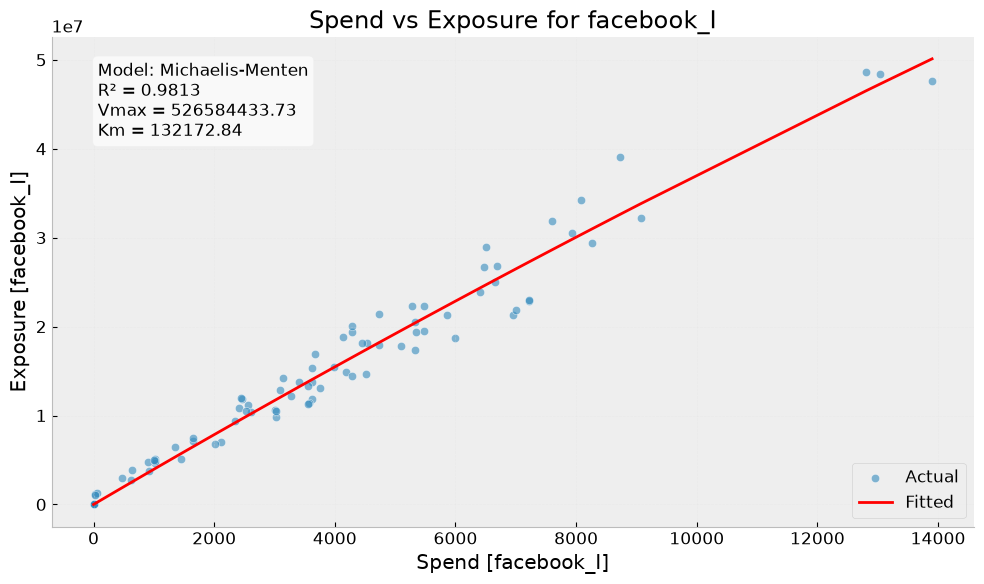

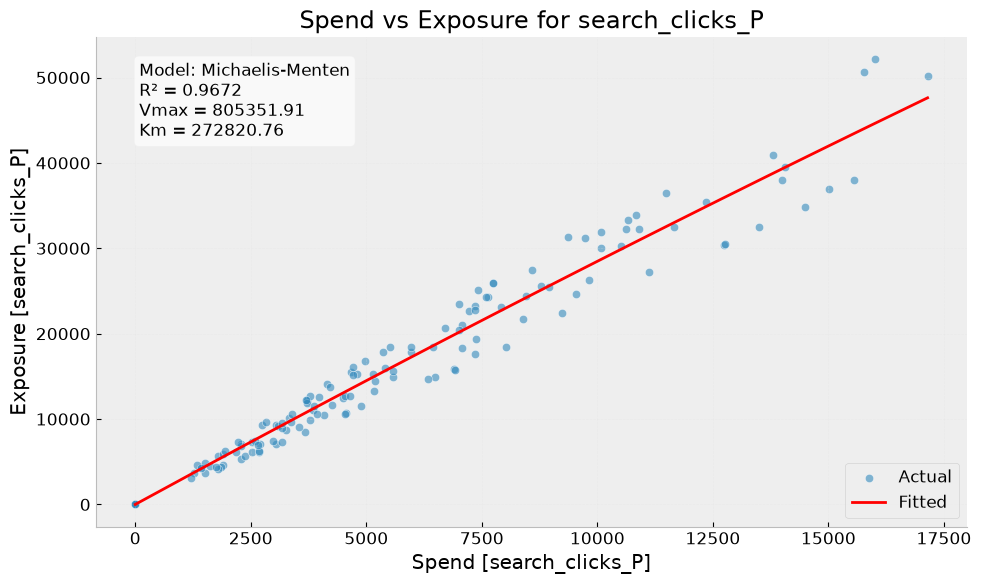

In [10]:
%matplotlib inline
from robyn.robyn import Robyn

robyn_model = Robyn(working_dir="output")
robyn_model.initialize(
    mmm_data=mmm_data,
    holidays_data=holidays_data,
    hyperparameters=hyperparameters,
)
robyn_model.feature_engineering();

In [12]:
import os
from robyn.modeling.entities.enums import Models, NevergradAlgorithm
from robyn.modeling.entities.modelrun_trials_config import TrialsConfig

robyn_model.train_models(
    trials_config=TrialsConfig(iterations=2000, trials=5),
    ts_validation=True,
    add_penalty_factor=False,
    rssd_zero_penalty=True,
    nevergrad_algo=NevergradAlgorithm.TWO_POINTS_DE,
    model_name=Models.RIDGE,
    cores=max(1, os.cpu_count() - 1),
)

INFO: Training models
2026-11-11 15:11:10,209 - robyn.robyn - INFO - Training models
2026-11-11 15:11:10,211 - robyn.modeling.base_model_executor - INFO - Initializing BaseModelExecutor
2026-11-11 15:11:10,212 - robyn.modeling.model_executor - INFO - Starting model execution with model_name=Models.RIDGE
2026-11-11 15:11:10,212 - robyn.modeling.base_model_executor - INFO - Input validation successful
2026-11-11 15:11:10,213 - robyn.modeling.base_model_executor - INFO - Preparing hyperparameters
2026-11-11 15:11:10,214 - robyn.modeling.base_model_executor - INFO - Completed hyperparameter preparation with 20 parameters to optimize
2026-11-11 15:11:10,214 - robyn.modeling.model_executor - INFO - Initializing Ridge model builder
2026-11-11 15:11:10,226 - robyn.modeling.model_executor - INFO - Building models with configured parameters
2026-11-11 15:11:10,227 - robyn.modeling.ridge.ridge_data_builder - INFO - Collecting hyperparameters for optimization...
Running trial 1 of 5: 100%|████████

DECOMP.RSSD NOT converged: sd@qt.20 0.054 <= 0.242 & |med@qt.20| 0.08 > -0.39
NRMSE NOT converged: sd@qt.20 0.008 <= 0.076 & |med@qt.20| 0.07 > -0.08


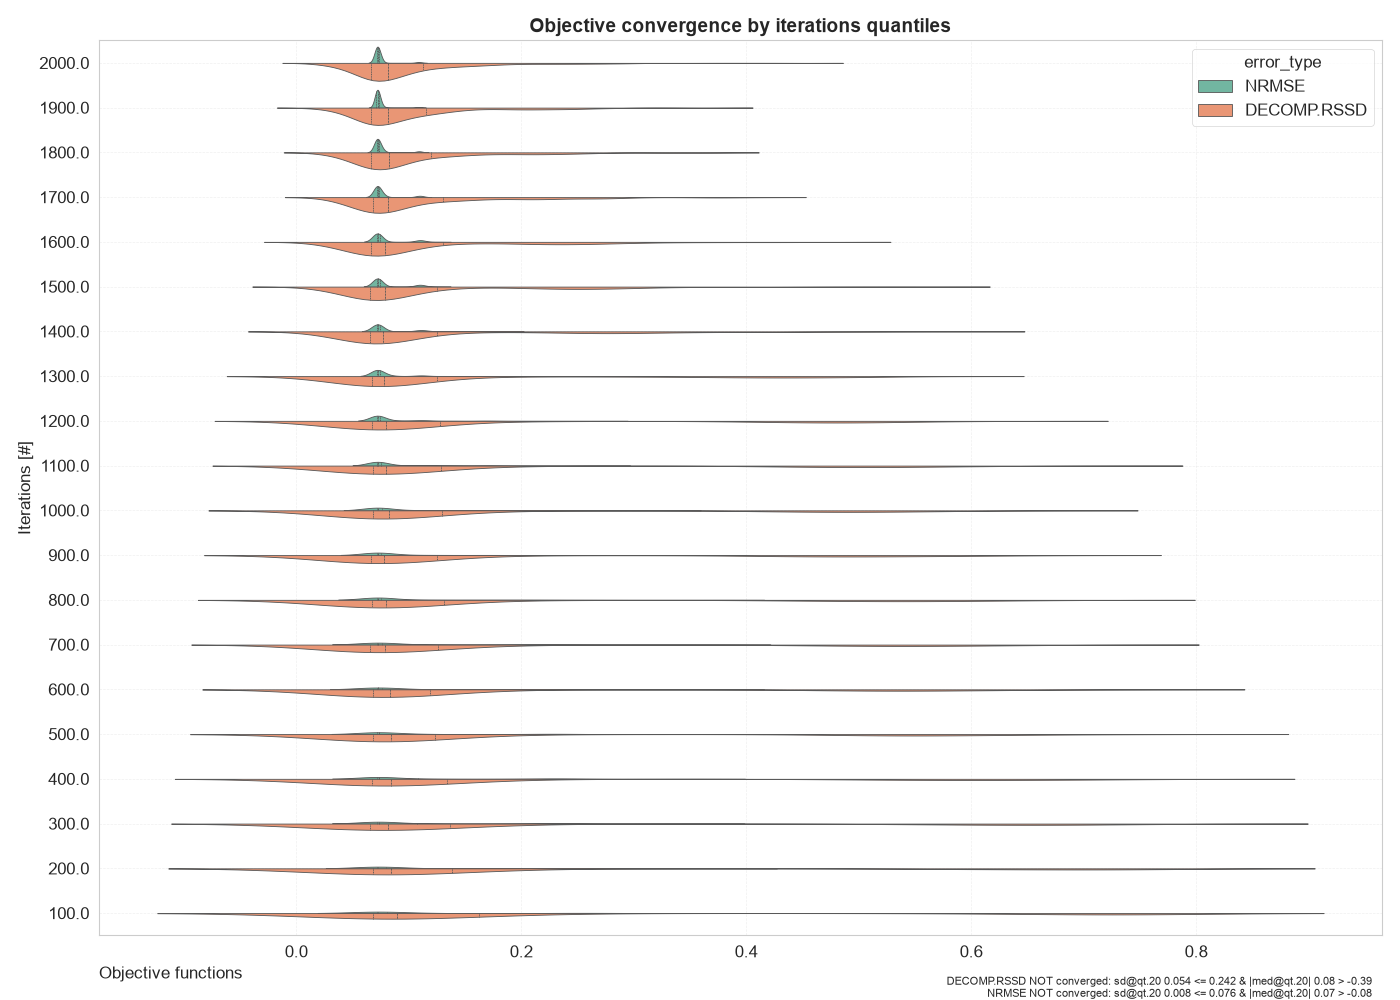

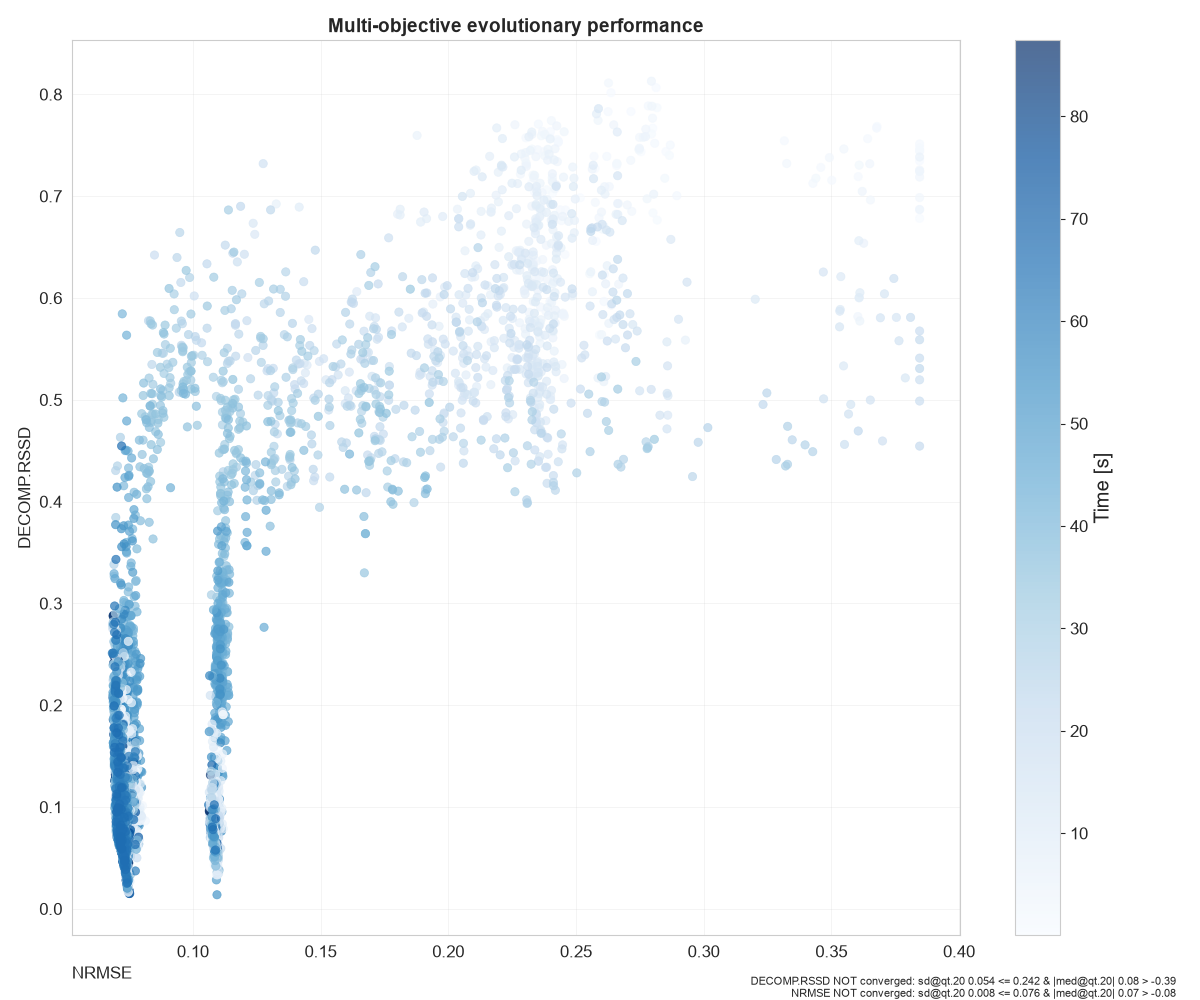

Grafikler output klasorune kaydedildi


In [14]:
import os
import base64
from IPython.display import Image, display

conv = robyn_model.model_outputs.convergence

# 1. Yakinsama mesajlari
for mesaj in conv["conv_msg"]:
    print(mesaj)

# 2. Grafikleri ekranda goster ve output klasorune kaydet
os.makedirs("output", exist_ok=True)
for ad in ["moo_distrb_plot", "moo_cloud_plot"]:
    resim = base64.b64decode(conv[ad])
    display(Image(resim))
    with open(f"output/{ad}.png", "wb") as f:
        f.write(resim)

print("Grafikler output klasorune kaydedildi")

INFO: Evaluating models
2026-11-11 16:31:36,938 - robyn.robyn - INFO - Evaluating models
2026-11-11 16:31:37 [INFO] Starting Pareto optimization
2026-11-11 16:31:37,119 - robyn.modeling.pareto.data_aggregator - INFO - Starting model data aggregation
2026-11-11 16:31:37 [INFO] Computing Pareto fronts
2026-11-11 16:31:39 [INFO] Pareto front computation completed
2026-11-11 16:31:39 [INFO] Preparing Pareto data
2026-11-11 16:31:39 [INFO] Number of Pareto-optimal solutions found: 8826
2026-11-11 16:31:39 [INFO] Selected 2 Pareto-fronts containing 194 candidates
2026-11-11 16:31:39 [INFO] Selected Pareto fronts: 3
2026-11-11 16:31:39 [INFO] Filtering data for selected Pareto fronts...
2026-11-11 16:31:39 [INFO] Pareto data preparation completed
2026-11-11 16:31:39,674 - robyn.modeling.pareto.response_curve - INFO - Calculating response curves for 970 models' media variables...
Processing rows: 100%|██████████| 970/970 [00:21<00:00, 44.90it/s] 
2026-11-11 16:32:03,036 - robyn.modeling.pareto

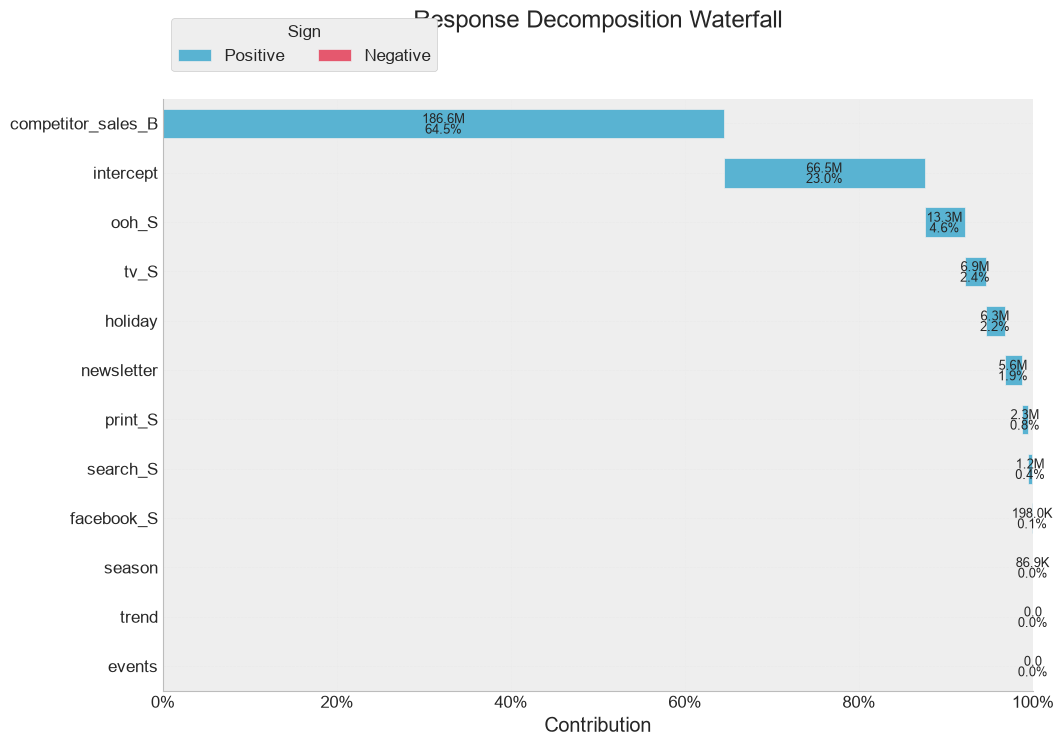

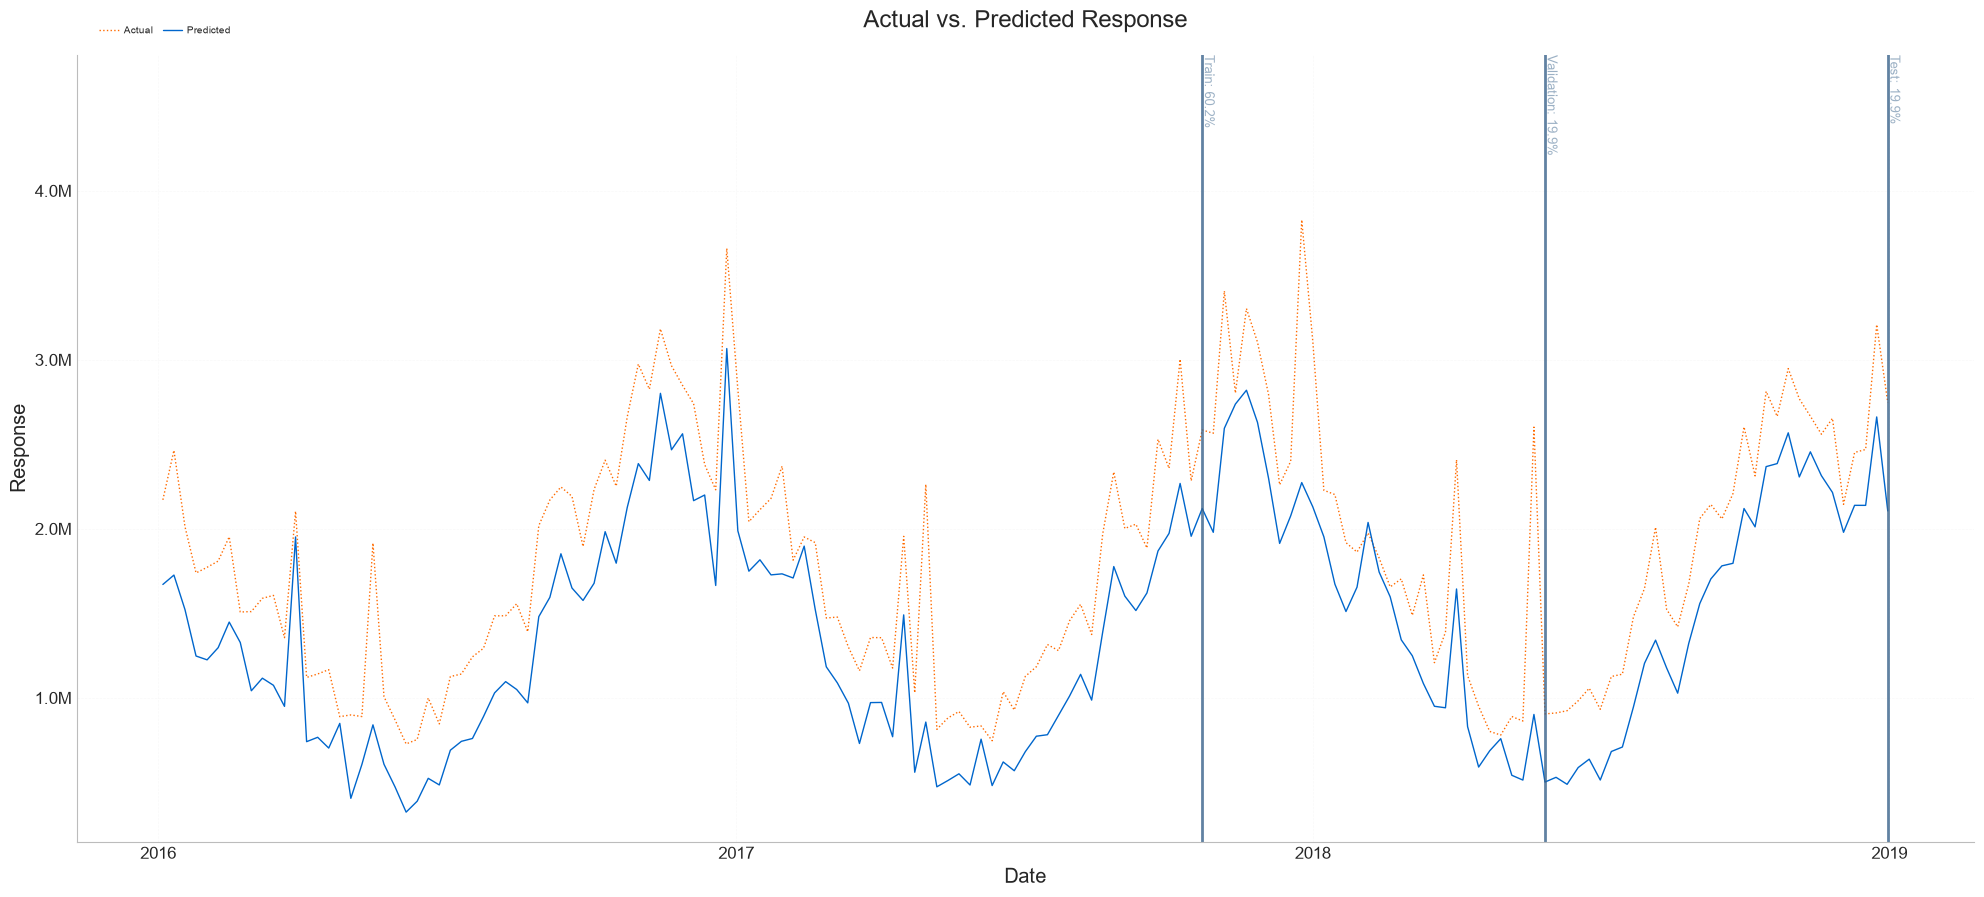

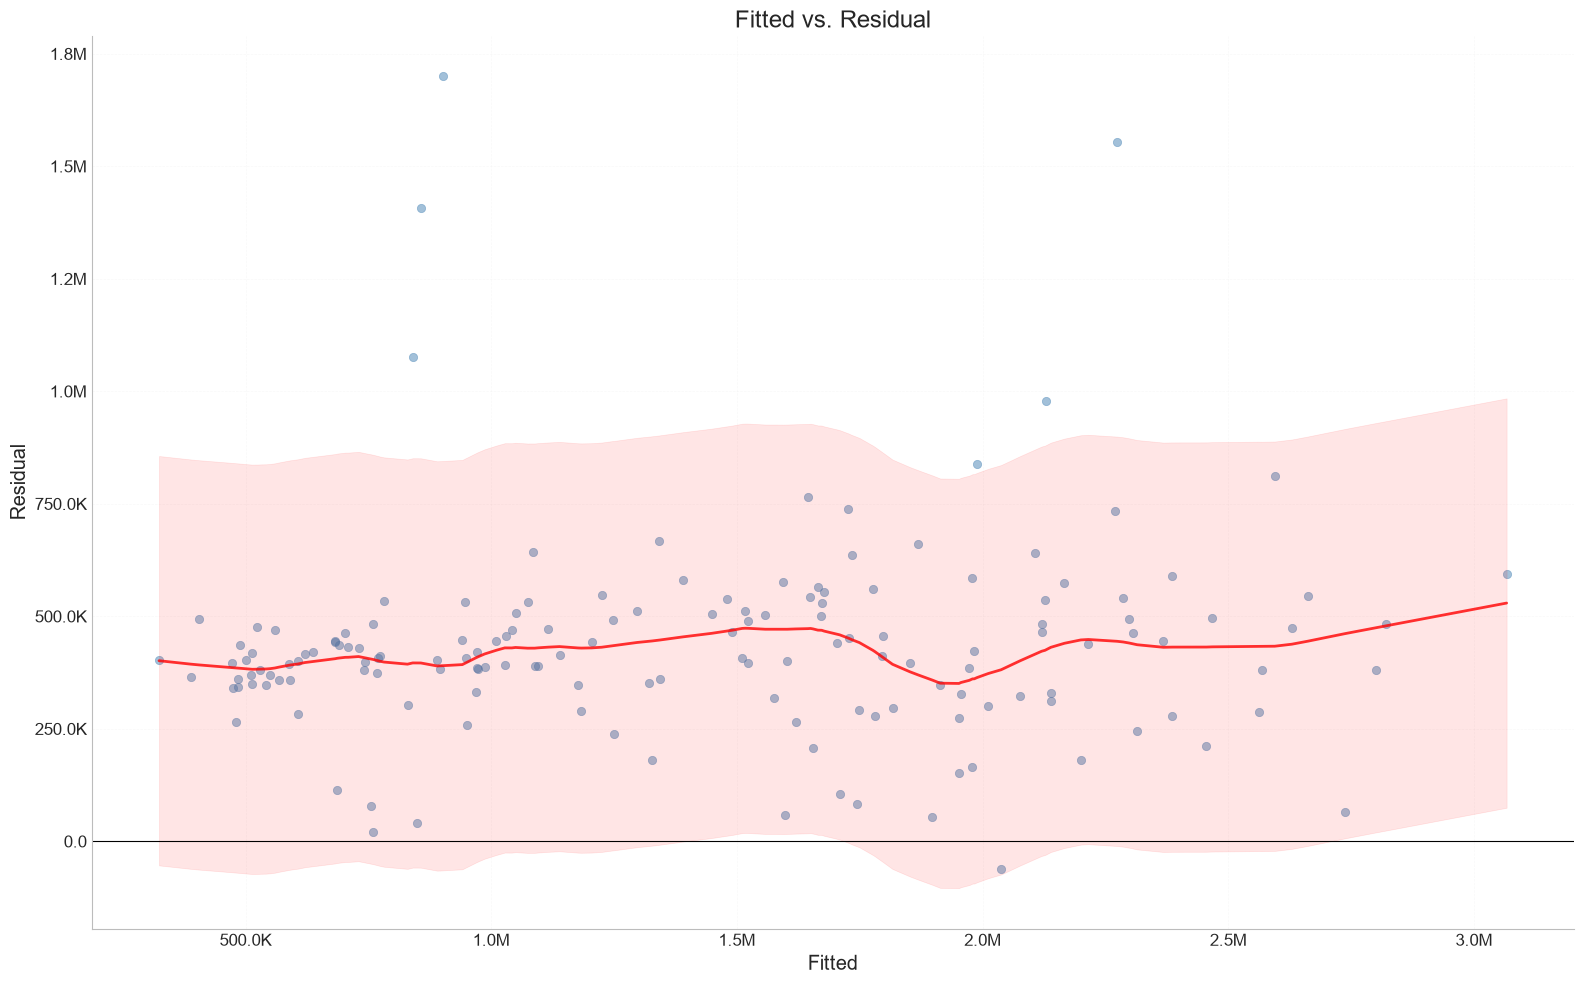

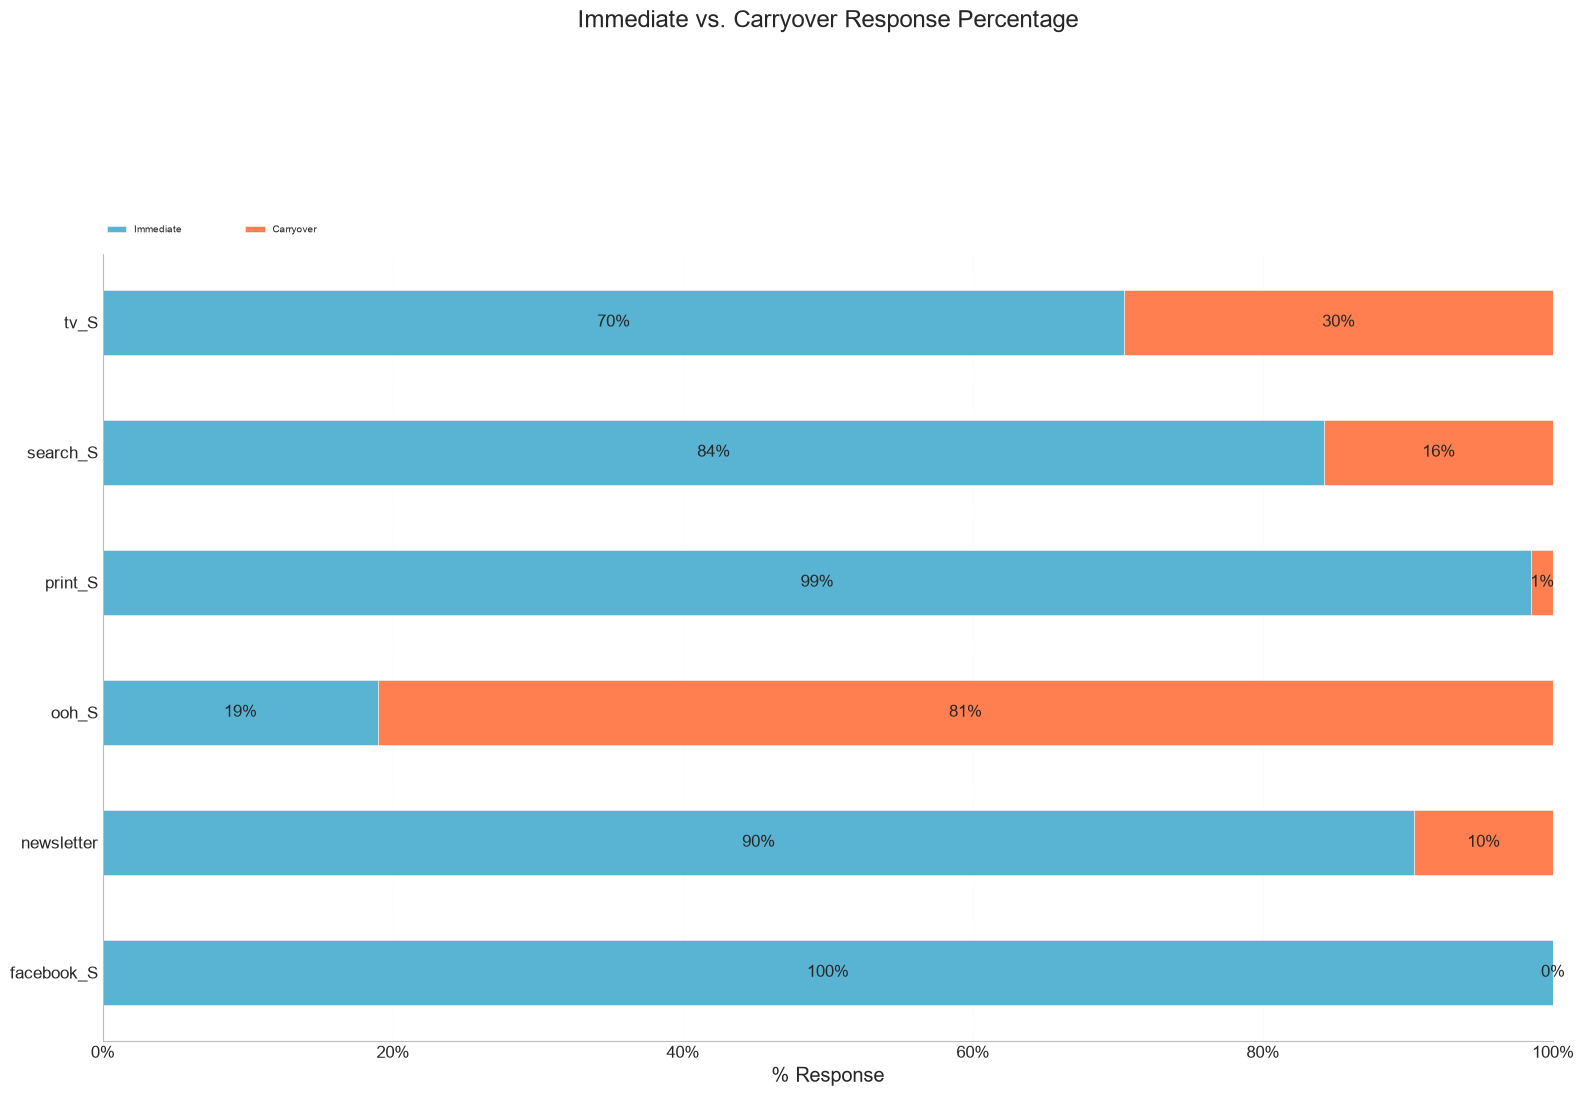

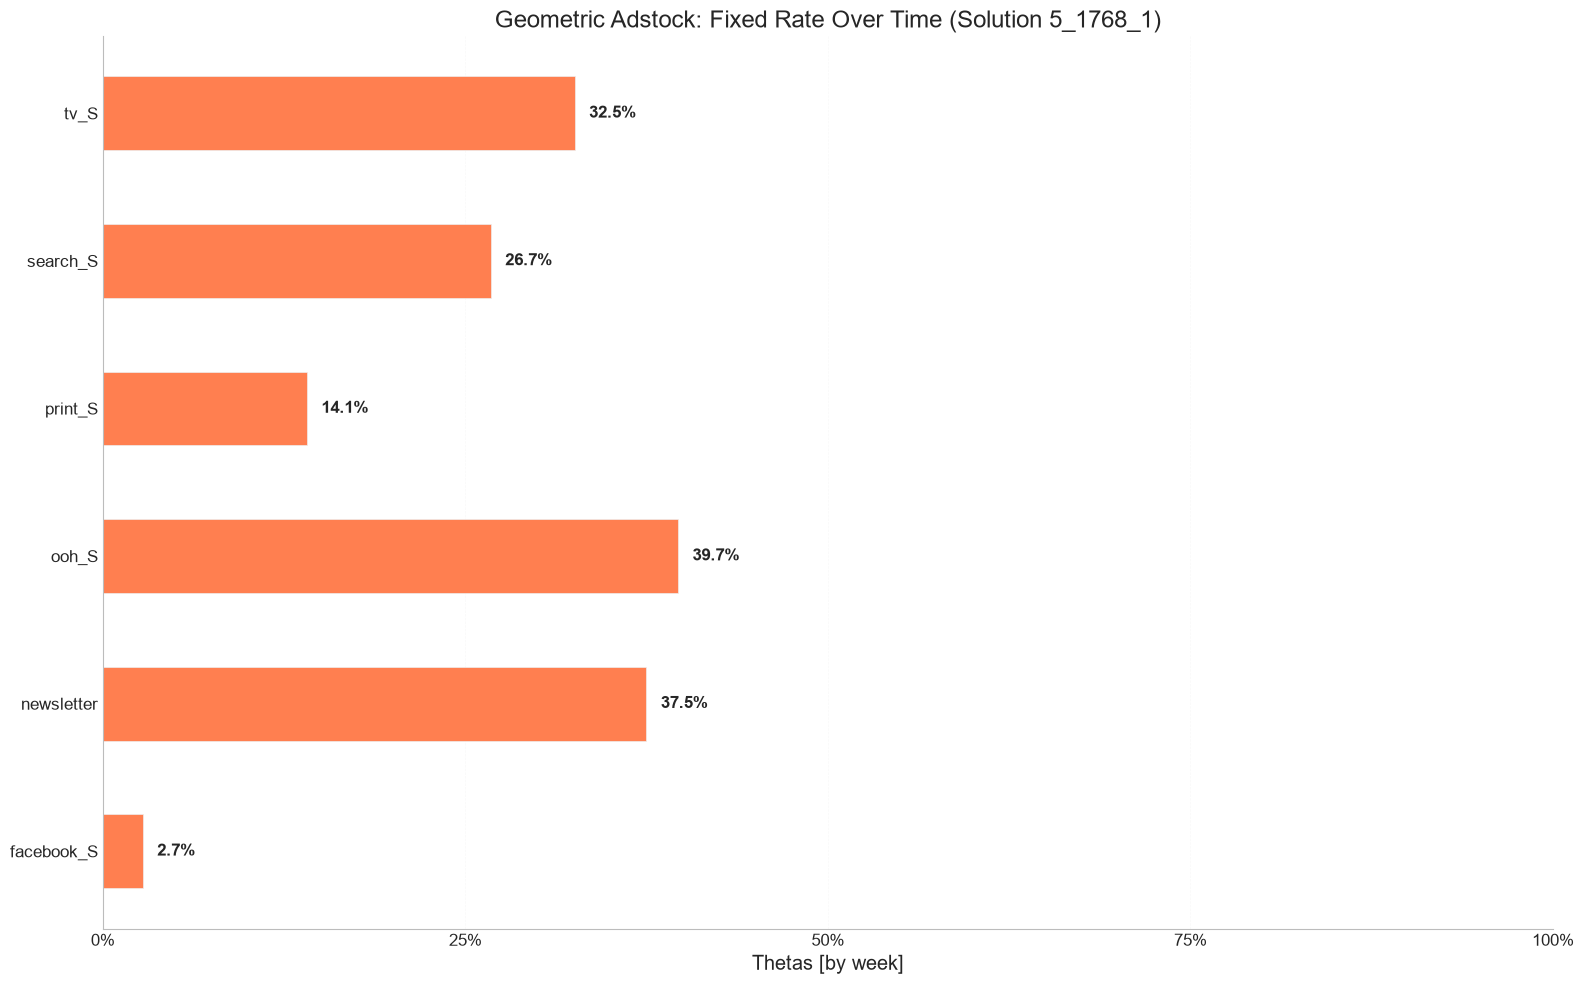

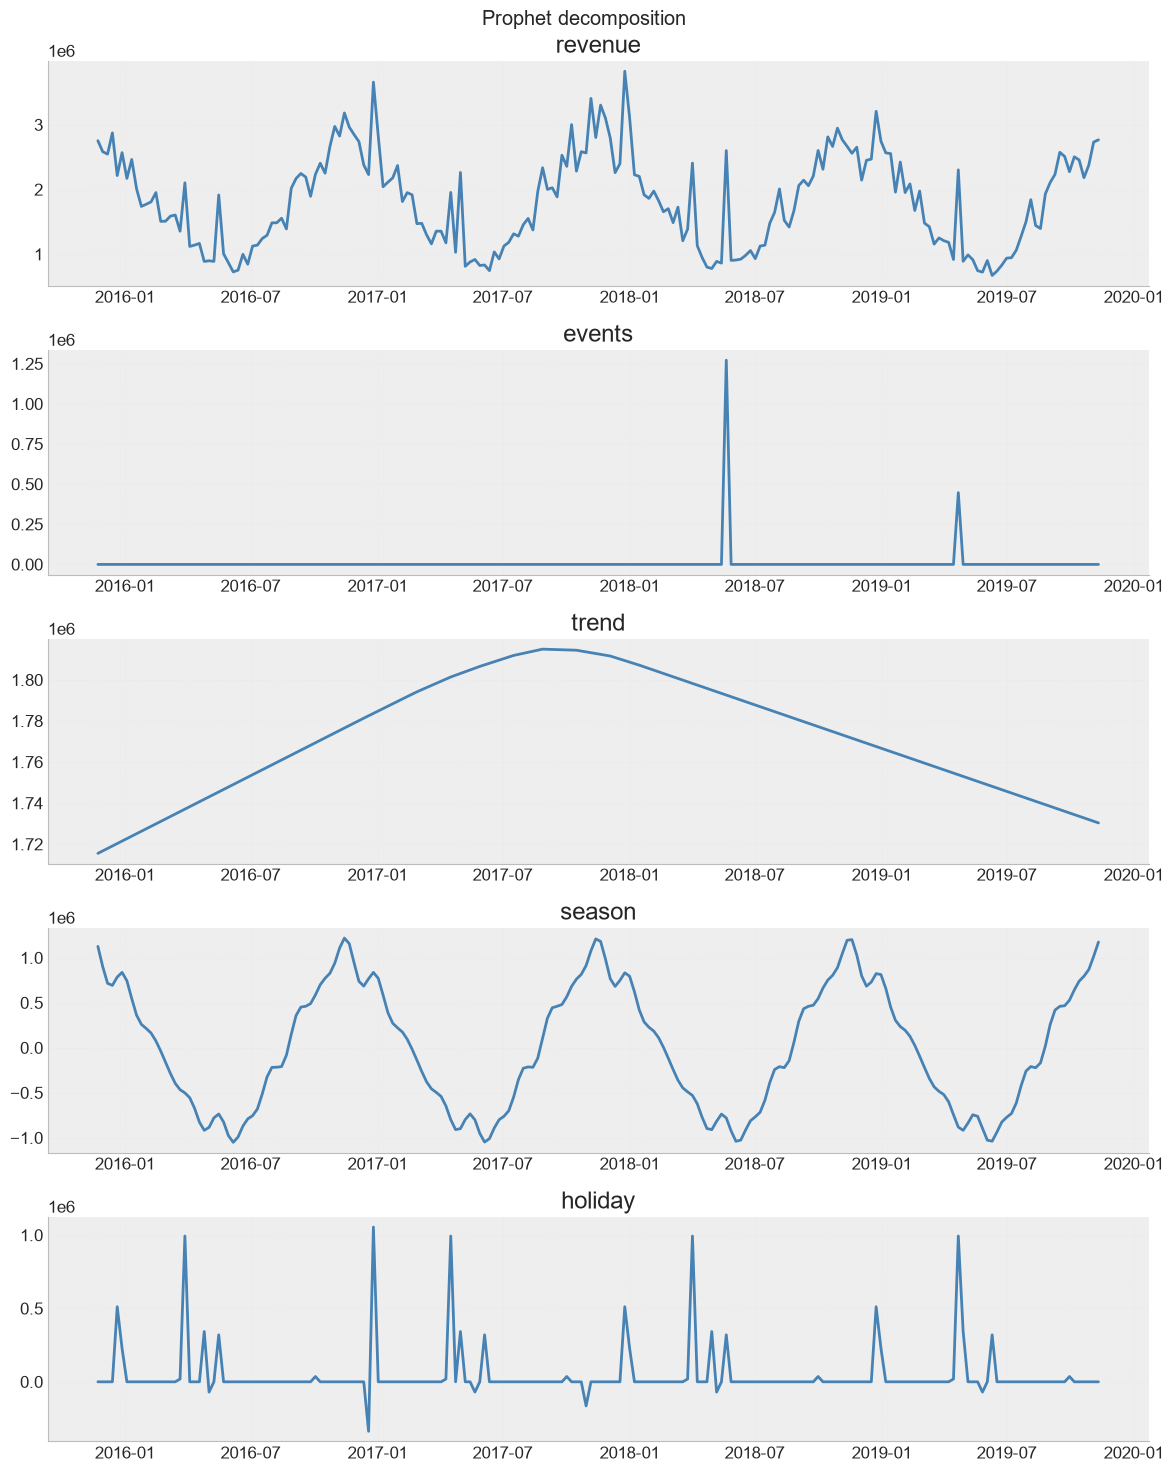

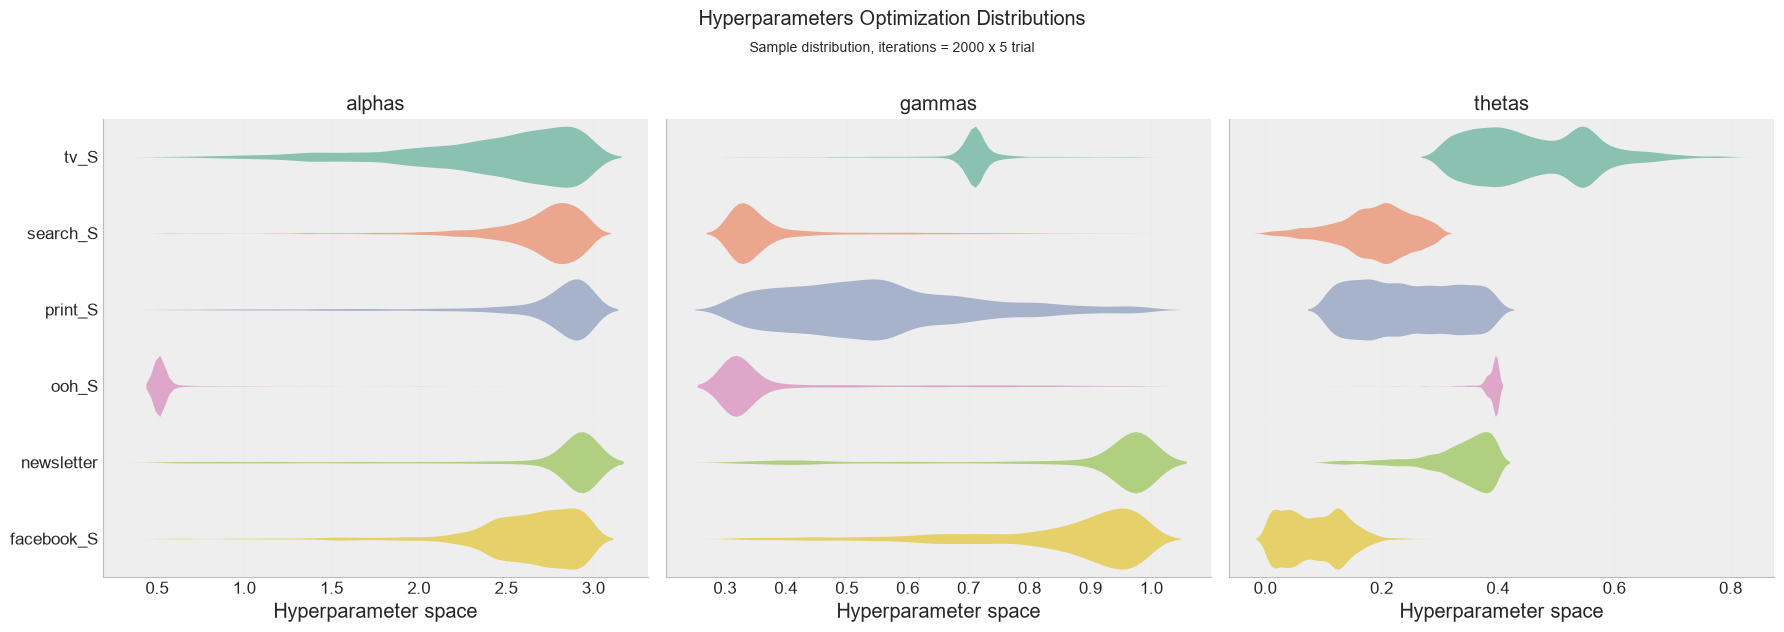

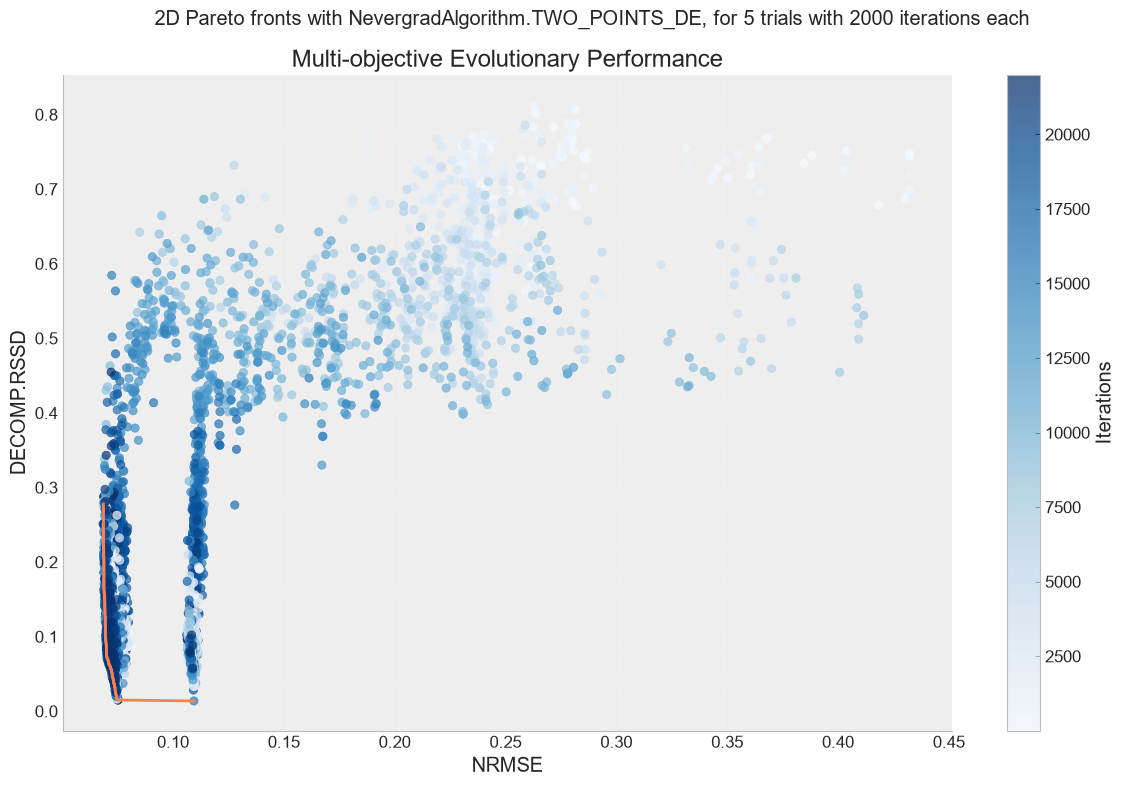

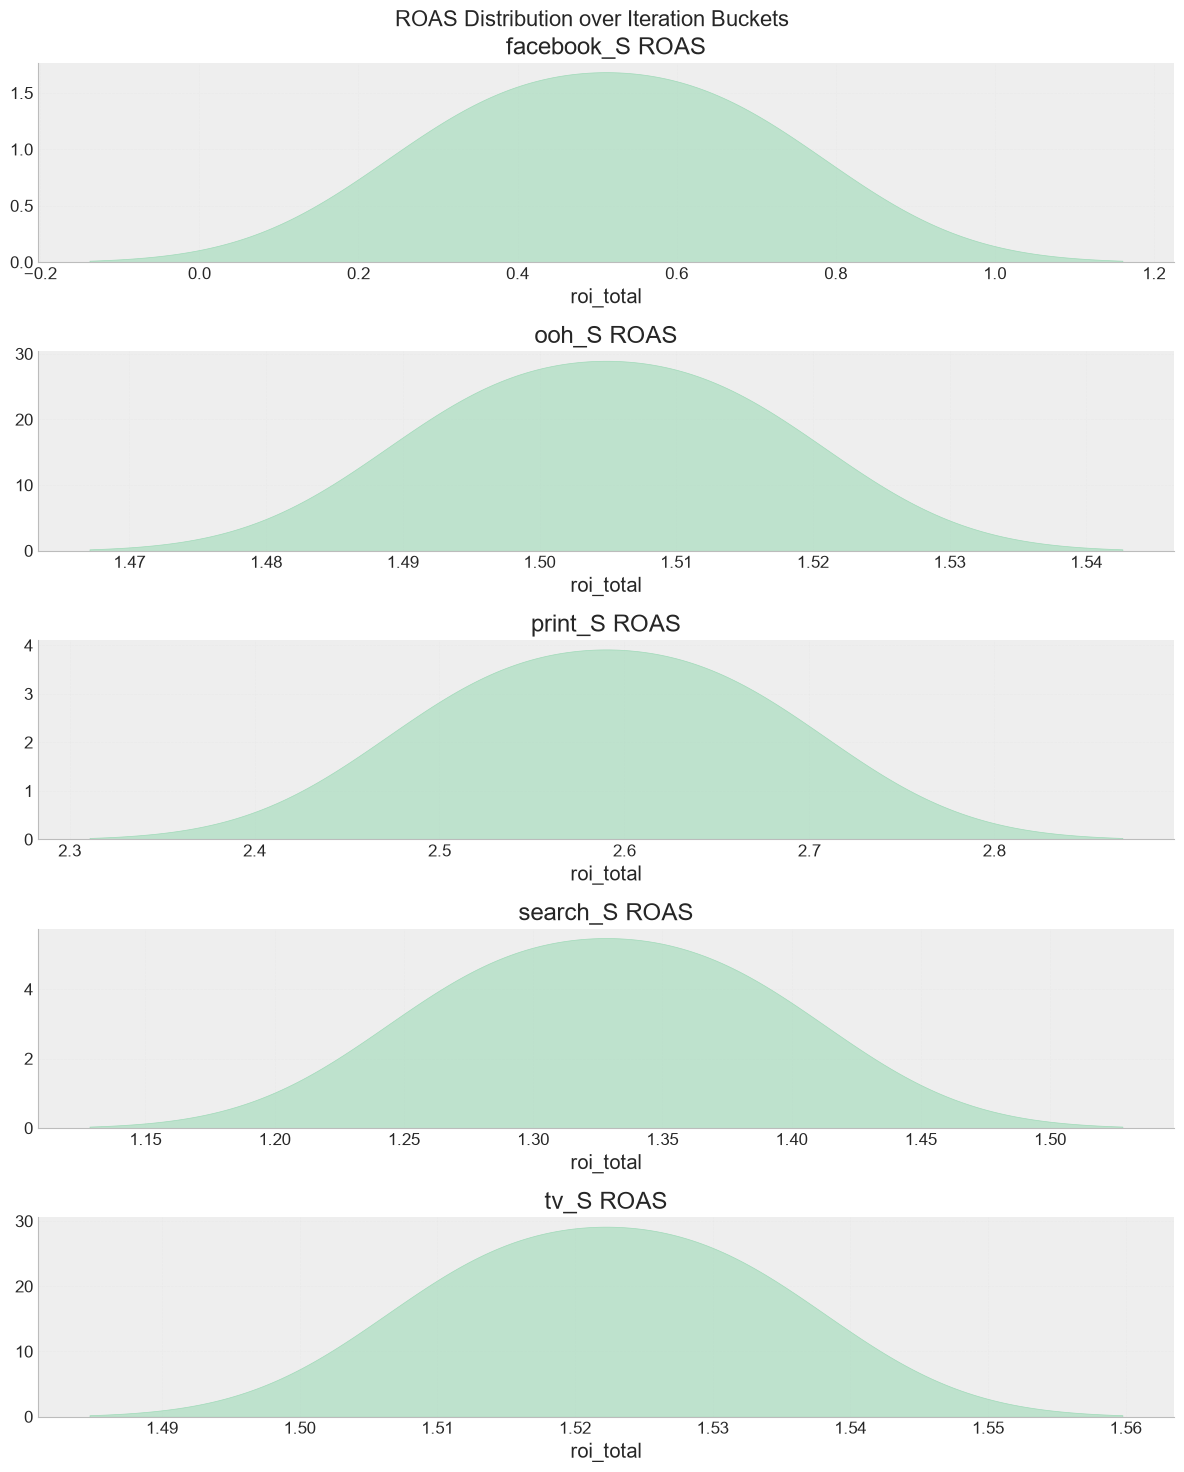

2026-11-11 16:33:27,172 - robyn.visualization.cluster_visualizer - WARNING - create_correlations_heatmap method is not implemented.


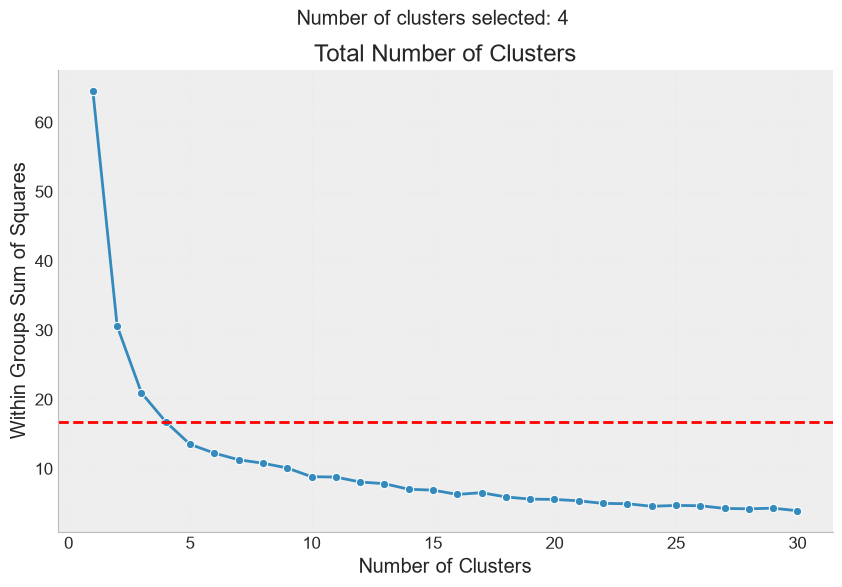

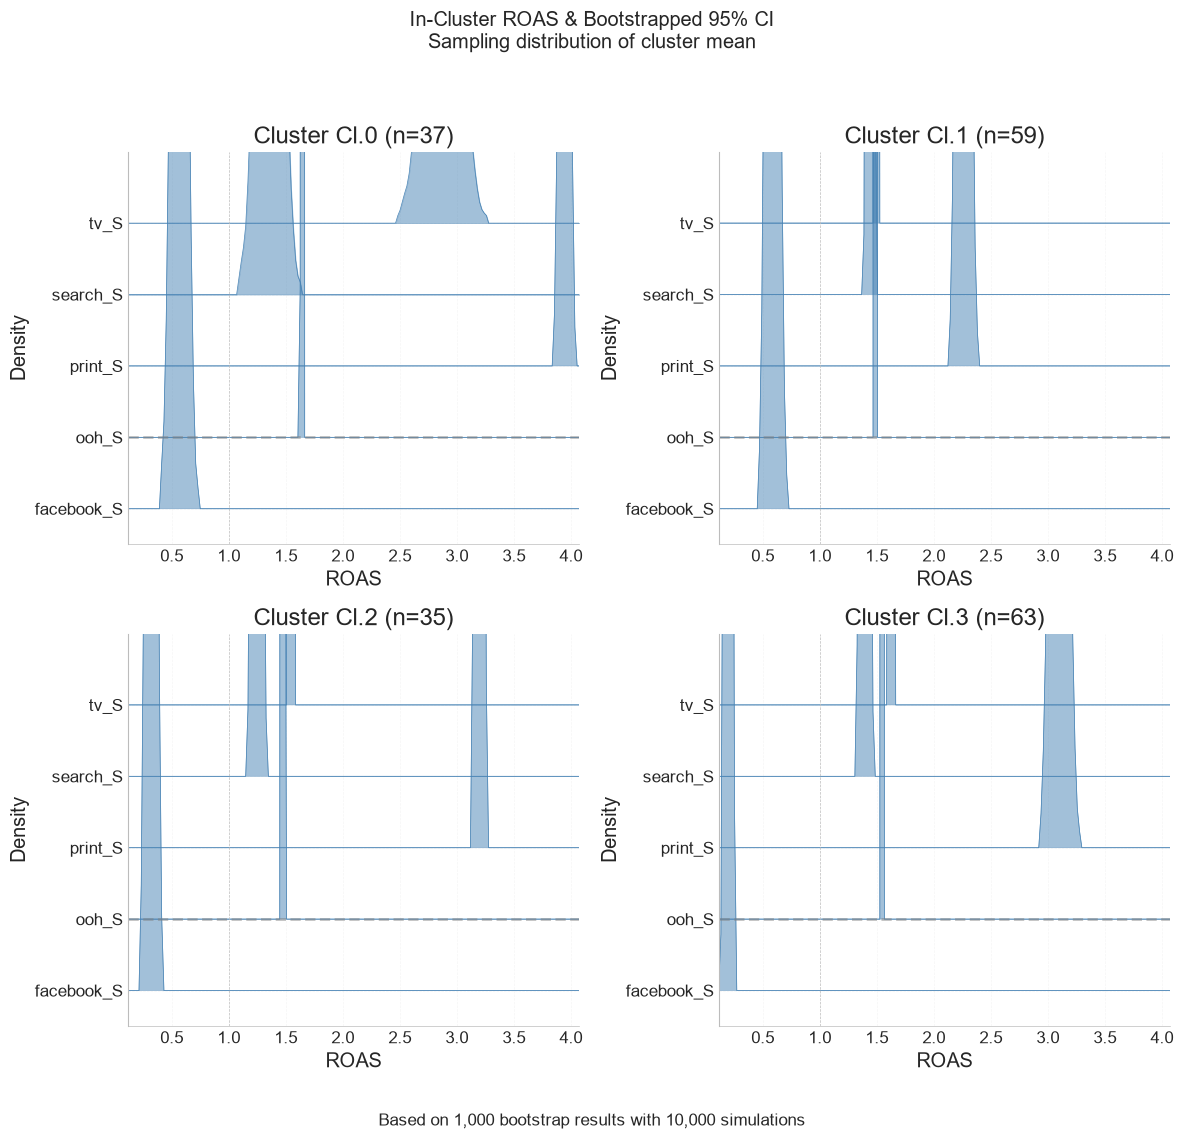

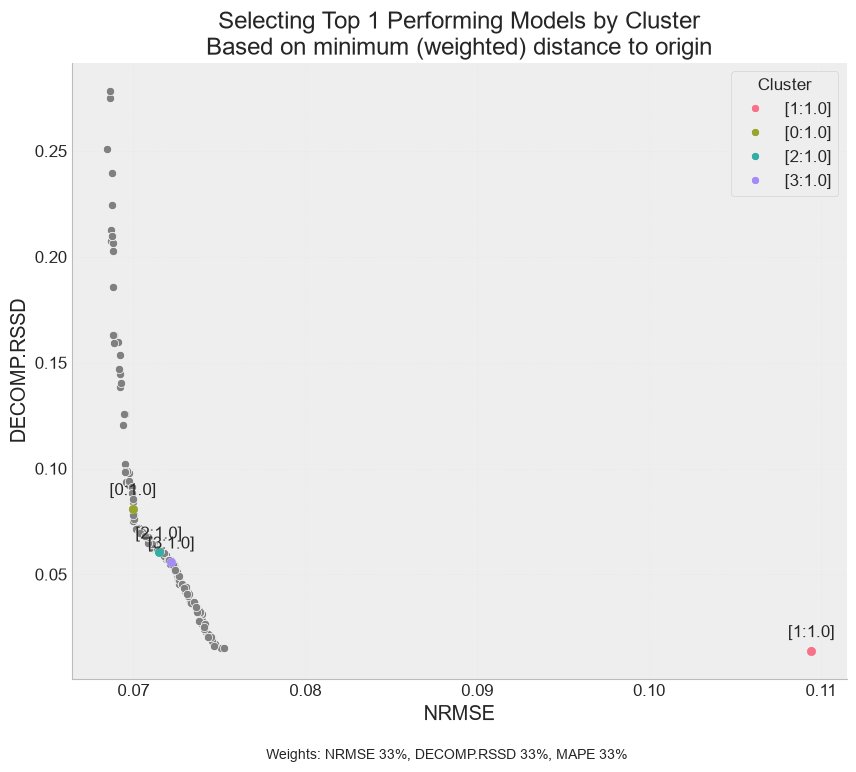

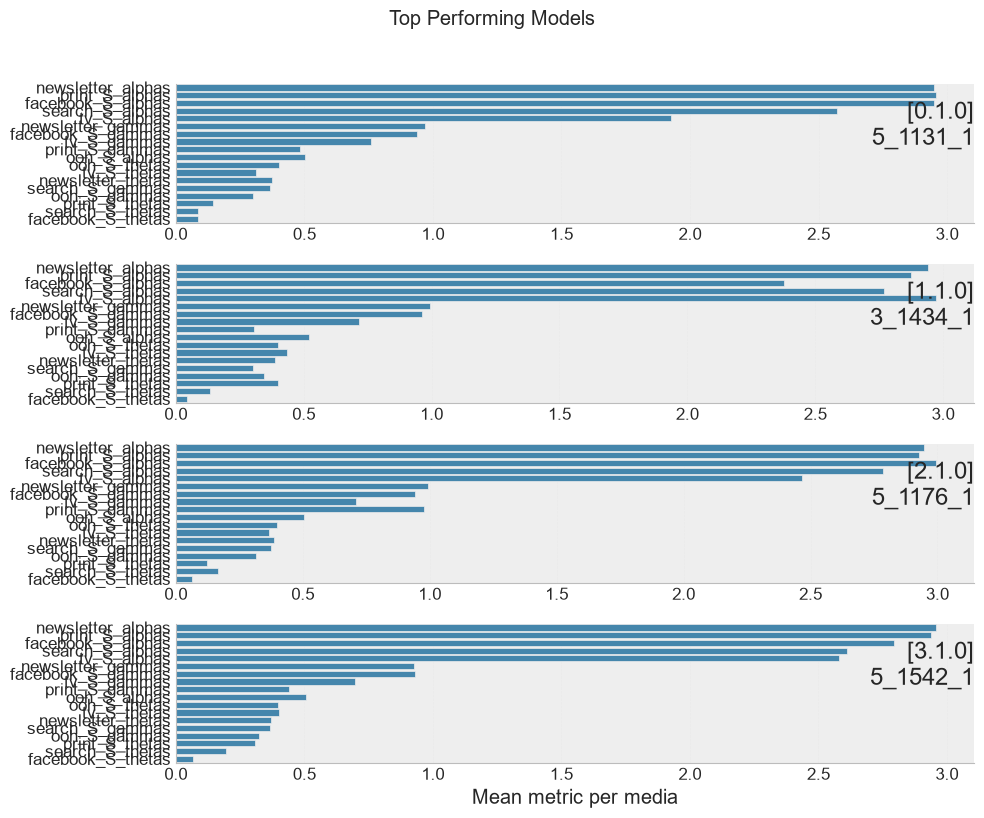

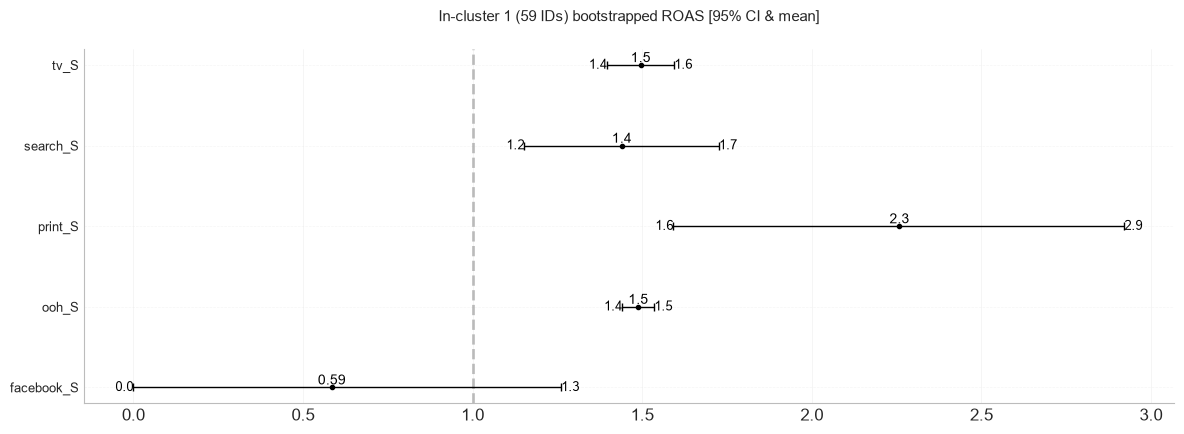

INFO: Model evaluation complete
2026-11-11 16:33:29,902 - robyn.robyn - INFO - Model evaluation complete


In [15]:
from robyn.modeling.clustering.clustering_config import ClusterBy, ClusteringConfig
from robyn.data.entities.enums import DependentVarType

robyn_model.evaluate_models(
    cluster_config=ClusteringConfig(
        dep_var_type=DependentVarType.REVENUE,
        cluster_by=ClusterBy.HYPERPARAMETERS,
        max_clusters=10,
        min_clusters=3,
        weights=[1.0, 1.0, 1.0],
    )
)

In [16]:
top = robyn_model.cluster_result.top_solutions
hp = robyn_model.pareto_result.result_hyp_param[["sol_id", "rsq_train", "rsq_test"]].drop_duplicates("sol_id")

ozet = (top.merge(hp, on="sol_id")
        [["cluster", "sol_id", "rsq_train", "rsq_test", "nrmse_train", "nrmse_test", "decomp.rssd"]]
        .sort_values("decomp.rssd").round(3).reset_index(drop=True))
ozet

,cluster,sol_id,rsq_train,rsq_test,nrmse_train,nrmse_test,decomp.rssd
0,1,3_1434_1,0.931,0.978,0.056,0.042,0.014
1,3,5_1542_1,0.933,0.845,0.055,0.113,0.056
2,2,5_1176_1,0.935,0.848,0.054,0.112,0.060
3,0,5_1131_1,0.936,0.842,0.054,0.114,0.081


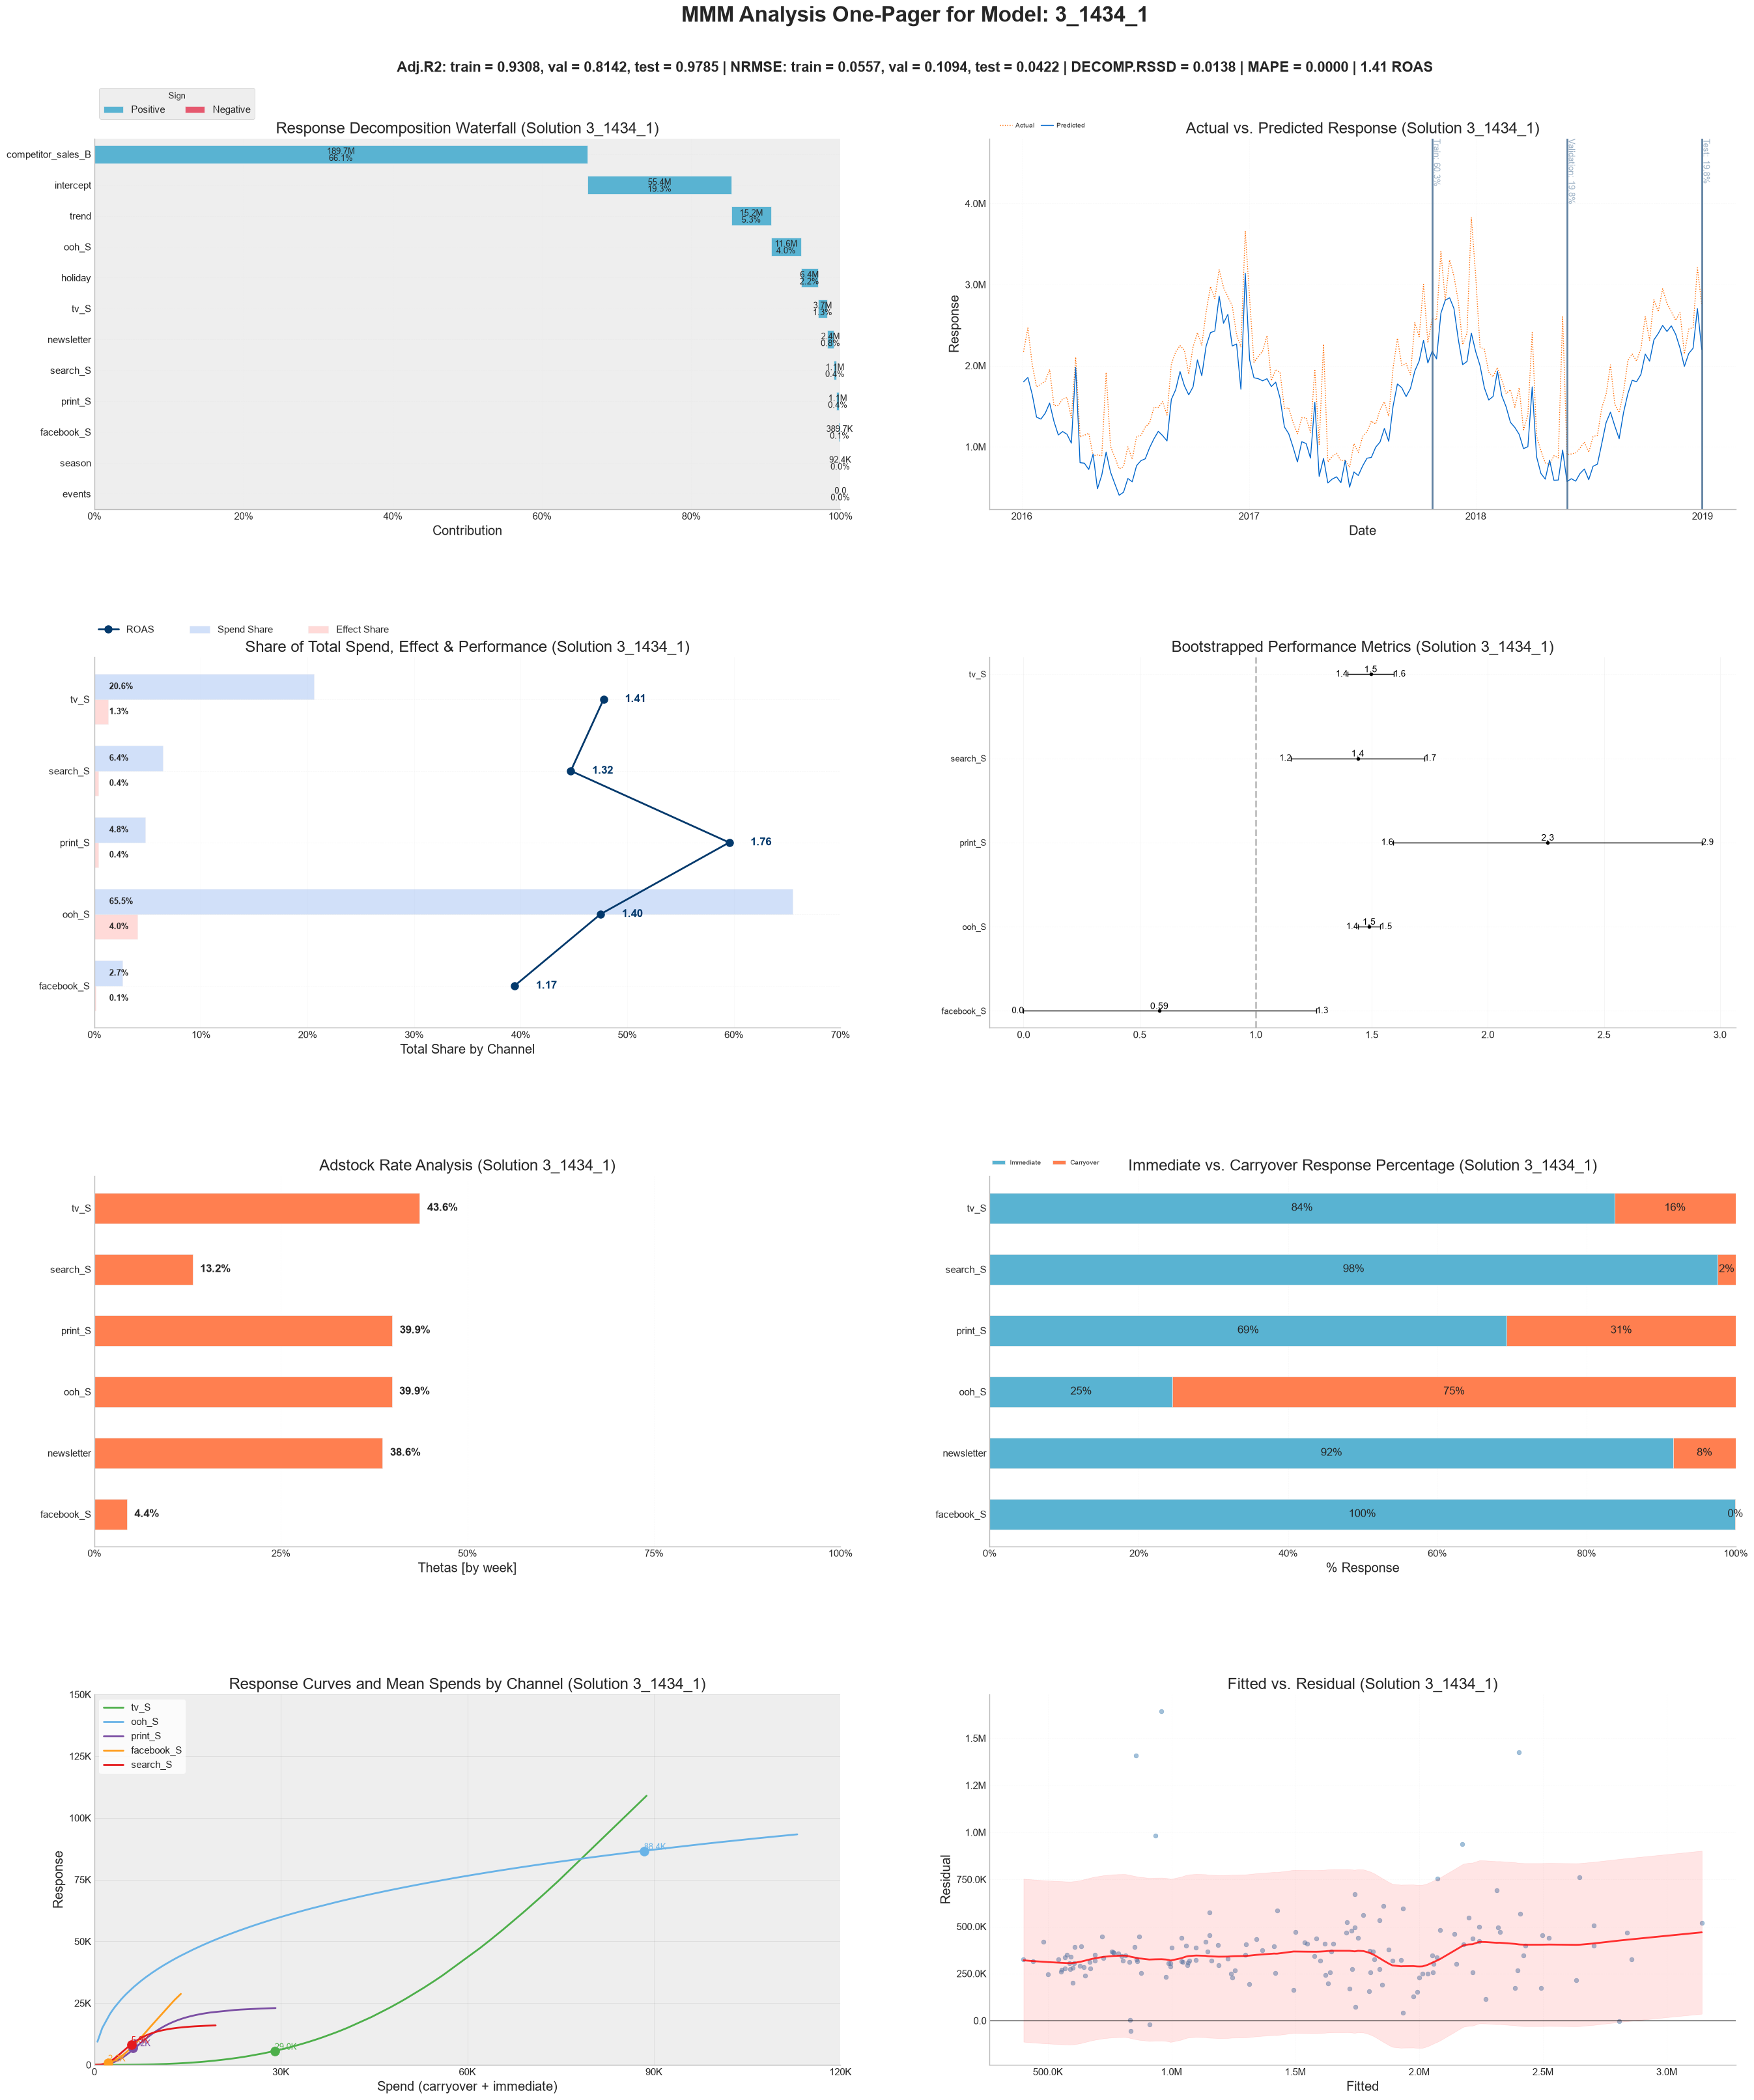

One-pager output klasorune kaydedildi


In [18]:
from IPython.display import display

figurler = robyn_model.generate_one_pager(solution_id="3_1434_1")
onepager = figurler[0]

display(onepager)
onepager.savefig("output/onepager_3_1434_1.png", dpi=100, bbox_inches="tight")
print("One-pager output klasorune kaydedildi")

INFO: Optimizing budget allocation
2026-11-11 17:18:45,490 - robyn.robyn - INFO - Optimizing budget allocation
INFO: Selected model for budget optimization: 3_1434_1
2026-11-11 17:18:45,501 - robyn.robyn - INFO - Selected model for budget optimization: 3_1434_1
2026-11-11 17:18:46,287 - robyn.visualization.allocator_visualizer - INFO - Initializing AllocatorPlotter


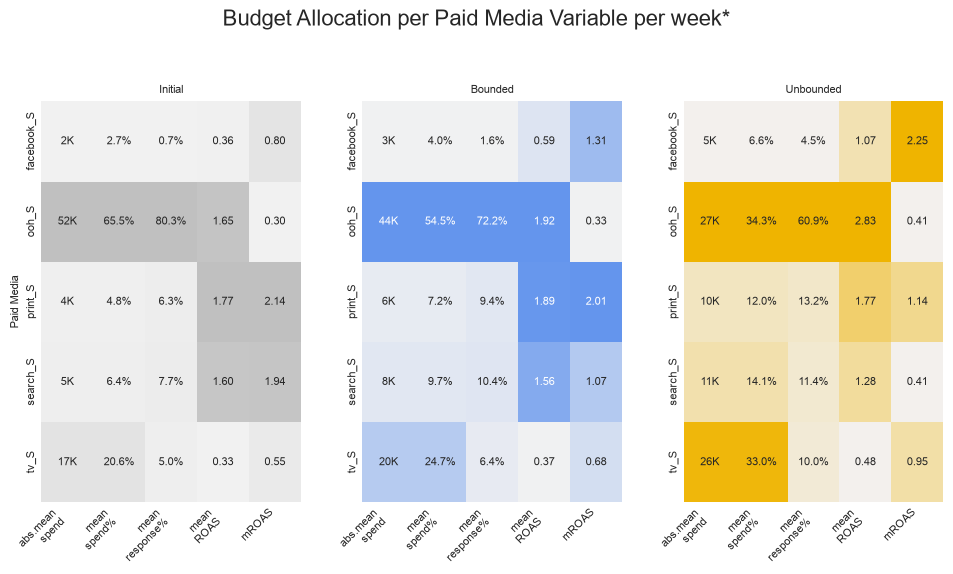

2026-11-11 17:19:12,034 - robyn.visualization.base_visualizer - INFO - Saving multiple plots to: C:\dev\robyn-mmm\output


In [ ]:
from robyn.allocator.entities.allocation_params import AllocatorParams
from robyn.allocator.constants import (
    SCENARIO_MAX_RESPONSE, CONSTRAINT_MODE_EQ, DATE_RANGE_ALL,
    DEFAULT_CONSTRAINT_MULTIPLIER, ALGO_SLSQP_AUGLAG,
)

allocator_params = AllocatorParams(
    scenario=SCENARIO_MAX_RESPONSE,
    total_budget=None,
    date_range=DATE_RANGE_ALL,
    channel_constr_low=[0.7, 0.7, 0.7, 0.7, 0.7],
    channel_constr_up=[1.2, 1.5, 1.5, 1.5, 1.5],
    channel_constr_multiplier=DEFAULT_CONSTRAINT_MULTIPLIER,
    optim_algo=ALGO_SLSQP_AUGLAG,
    maxeval=100000,
    constr_mode=CONSTRAINT_MODE_EQ,
    plots=False,
)

butce = robyn_model.optimize_budget(
    allocator_params=allocator_params,
    select_model="3_1434_1",
    display_plots=False,
)
print("Butce optimizasyonu tamamlandi")